In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

In [2]:
# dataset source: https://www.kaggle.com/datasets/hellbuoy/online-retail-customer-clustering
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "hellbuoy/online-retail-customer-clustering",
    "OnlineRetail.csv",
    pandas_kwargs={"encoding": "ISO-8859-1"},
)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [4]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
# Check negative or 0 Quantity
# Assume: 0 is retured/cancelled, negative is anomaly
df_neg_quantity = df[df['Quantity'] <= 0]
print("Retured/Cancelled/Anomaly: ")
display(df_neg_quantity[['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'CustomerID']].head())

# Check 0 UnitPrice (assume: free unit)
df_zero_price = df[df['UnitPrice'] <= 0]
print("\nSampel data UnitPrice <= 0:")
display(df_zero_price[['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'CustomerID']].head())

Retured/Cancelled/Anomaly: 


,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID
141,C536379,D,-1,27.50,14527.0
154,C536383,35004C,-1,4.65,15311.0
235,C536391,22556,-12,1.65,17548.0
236,C536391,21984,-24,0.29,17548.0
237,C536391,21983,-24,0.29,17548.0



Sampel data UnitPrice <= 0:


,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID
622,536414,22139,56,0.0,NaN
1970,536545,21134,1,0.0,NaN
1971,536546,22145,1,0.0,NaN
1972,536547,37509,1,0.0,NaN
1987,536549,85226A,1,0.0,NaN


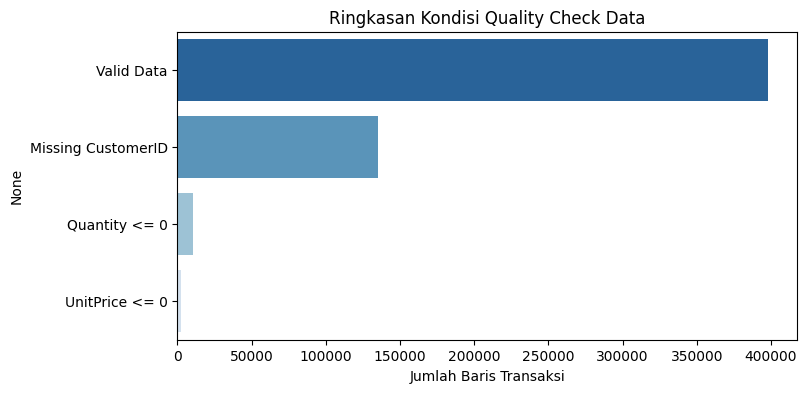

In [6]:
valid_mask = (df['Quantity'] > 0) & (df['UnitPrice'] > 0) & (df['CustomerID'].notnull())
data_status = pd.Series({
    'Valid Data': valid_mask.sum(),
    'Missing CustomerID': df['CustomerID'].isnull().sum(),
    'Quantity <= 0': (df['Quantity'] <= 0).sum(),
    'UnitPrice <= 0': (df['UnitPrice'] <= 0).sum()
})

plt.figure(figsize=(8, 4))
sns.barplot(x=data_status.values, y=data_status.index, palette='Blues_r', hue=data_status.index, legend=False)
plt.title('Ringkasan Kondisi Quality Check Data')
plt.xlabel('Jumlah Baris Transaksi')
plt.show()